In [1]:
%%capture
!pip install sacrebleu
!pip install transformers==4.40.2
!pip install sentencepiece
!pip install indic-nlp-library
!pip install torch>=1.10.0
!pip install datasets
!pip install tqdm
!pip install evaluate

In [2]:
import sacrebleu
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM, BitsAndBytesConfig
from transformers import logging as hf_logging
from huggingface_hub import list_repo_refs, notebook_login
from datasets import load_dataset, get_dataset_split_names, concatenate_datasets, DatasetDict
from tqdm import tqdm
import os

import time
import logging
import gc
import copy
import functools

import evaluate
from sacrebleu.metrics import CHRF

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [3]:
# for reproducibility
torch.manual_seed(42)
np.random.seed(42)

In [4]:
# Thanks chatgpt for this helpful method
def setup_notebook_logger():
    logger = logging.getLogger()
    logger.setLevel(logging.INFO)

    if logger.hasHandlers():
        logger.handlers.clear()

    handler = logging.StreamHandler()
    handler.setLevel(logging.INFO)

    formatter = logging.Formatter("[%(asctime)s] [%(levelname)s] %(message)s",
                                  datefmt="%H:%M:%S")
    handler.setFormatter(formatter)

    logger.addHandler(handler)
    return logger

logger = setup_notebook_logger()

# Test
logger.info("Notebook logger is working ✅")

[19:16:00] [INFO] Notebook logger is working ✅


In [5]:
def log_time(func):
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        start = time.time()
        result = func(*args, **kwargs)
        end = time.time()
        logger.info(f"{func.__name__}() took {end - start:.2f} seconds")
        return result
    return wrapper

In [6]:
DATASET_REPO = "umairhassan02/coco-captions-subset-59k-translated-final"
REFINED_DATASET_REPO = "umairhassan02/coco-captions-subset-refined"

In [7]:
dataset = load_dataset(DATASET_REPO)

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Generating train split:   0%|          | 0/292907 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25014 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/31 [00:00<?, ?it/s]

In [8]:
refined_dataset = load_dataset(REFINED_DATASET_REPO)

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Generating train split:   0%|          | 0/292907 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25014 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/31 [00:00<?, ?it/s]

In [10]:
bleu_metric = evaluate.load("bleu")
chrf_metric = evaluate.load("chrf")
sacrebleu_metric = evaluate.load("sacrebleu")

In [11]:
def calculate_metric_batched(metric, dataset, batch_size=1000):
    """
    Calculate a metric over the entire dataset in batches.
    Returns the aggregated score.
    """

    scores = []

    for split in ['validation', 'train']:
      n = len(dataset[split])
      for start in tqdm(range(0, n, batch_size)):
          end = min(start + batch_size, n)
          subset = dataset[split].select(range(start, end))
          predictions = subset['translated_captions']
          references = [[ref] for ref in subset['references']]  # ensure list of list
          result = metric.compute(predictions=predictions, references=references)
          scores.append(result)

    logger.info(f"total size of scores: {len(scores)}, batch size: {batch_size}")
    # Aggregate scores
    # For BLEU and SacreBLEU, average the scores
    if "bleu" in scores[0]:
        avg_score = sum(s["bleu"] for s in scores) / len(scores)
        return avg_score
    elif "score" in scores[0]:  # chrF
        avg_score = sum(s["score"] for s in scores) / len(scores)
        return avg_score
    else:
        return scores

In [12]:
#metrics used in original QE pipeline
@log_time
def calculate_qe_metrics(metric_list, dataset):
  all_scores = {}
  for metric in tqdm(metric_list):
    logger.info(f"calculating {metric} score")
    train_scores = list(dataset['train'][metric])
    val_scores = list(dataset['validation'][metric])
    metric_scores = train_scores + val_scores
    logger.info(f"{metric}: {np.mean(metric_scores)}")
    all_scores[metric] = {
        'mean': np.mean(metric_scores),
        'max': np.max(metric_scores),
        'min': np.min(metric_scores),
        'std': np.std(metric_scores),
        'low scores': np.sum(np.array(metric_scores) < 0.7)
    }
  return all_scores

In [18]:
@log_time
def calculate_standard_metrics(metric_hash, dataset):
    all_scores = {}
    for metric_name, method in metric_hash.items():
        logger.info(f"calculating {metric_name}")
        metric_score = calculate_metric_batched(method, dataset)
        all_scores[metric_name] = metric_score
    return all_scores

In [14]:
standard_metrics = {
    'bleu_metric': bleu_metric,
    'chrf_metric':  chrf_metric,
    'sacrebleu_metric': sacrebleu_metric
}

qe_metric_list = ['comet_score', 'bert_score', 'clip_score', 'final_score']

In [19]:
standard_metric_scores = calculate_standard_metrics(standard_metrics, dataset)

[19:29:55] [INFO] calculating bleu_metric
100% 26/26 [00:01<00:00, 13.82it/s]
100% 293/293 [00:21<00:00, 13.45it/s]
[19:30:19] [INFO] total size of scores: 319, batch size: 1000
[19:30:19] [INFO] calculating chrf_metric
100% 26/26 [00:03<00:00,  7.32it/s]
100% 293/293 [00:30<00:00,  9.71it/s]
[19:30:52] [INFO] total size of scores: 319, batch size: 1000
[19:30:52] [INFO] calculating sacrebleu_metric
100% 26/26 [00:01<00:00, 17.87it/s]
100% 293/293 [00:18<00:00, 15.69it/s]
[19:31:12] [INFO] total size of scores: 319, batch size: 1000
[19:31:12] [INFO] calculate_standard_metrics() took 77.52 seconds


In [20]:
standard_metric_scores

{'bleu_metric': 0.5193201326571998,
 'chrf_metric': 73.23294351318378,
 'sacrebleu_metric': 51.93201326571997}

In [21]:
metric_list = ['comet_score', 'bert_score', 'clip_score', 'final_score']
qe_metrics = calculate_qe_metrics(metric_list, dataset)

  0% 0/4 [00:00<?, ?it/s][19:31:37] [INFO] calculating comet_score score
[19:31:37] [INFO] comet_score: 0.7552757840607398
 25% 1/4 [00:00<00:00,  8.14it/s][19:31:37] [INFO] calculating bert_score score
[19:31:37] [INFO] bert_score: 0.9699149075993214
 50% 2/4 [00:00<00:00,  8.36it/s][19:31:37] [INFO] calculating clip_score score
[19:31:37] [INFO] clip_score: 0.7486534548987823
 75% 3/4 [00:00<00:00,  8.63it/s][19:31:37] [INFO] calculating final_score score
[19:31:37] [INFO] final_score: 0.8398069676437808
100% 4/4 [00:00<00:00,  8.56it/s]
[19:31:37] [INFO] calculate_qe_metrics() took 0.47 seconds


In [22]:
qe_metrics

{'comet_score': {'mean': 0.7552757840607398,
  'max': 0.8917399644851685,
  'min': 0.0714404508471489,
  'std': 0.09396871545190985,
  'low scores': 80344},
 'bert_score': {'mean': 0.9699149075993214,
  'max': 1.0000004768371582,
  'min': 0.6642032861709595,
  'std': 0.022775477096095016,
  'low scores': 4},
 'clip_score': {'mean': 0.7486534548987823,
  'max': 1.0,
  'min': 0.011079814167598801,
  'std': 0.12408256403517166,
  'low scores': 98003},
 'final_score': {'mean': 0.8398069676437808,
  'max': 0.9499266624450684,
  'min': 0.430522023554701,
  'std': 0.04982420094876791,
  'low scores': 3572}}

In [23]:
standard_metric_refined = calculate_standard_metrics(standard_metrics, refined_dataset)

[19:32:52] [INFO] calculating bleu_metric
100% 26/26 [00:02<00:00, 12.97it/s]
100% 293/293 [00:22<00:00, 12.78it/s]
[19:33:17] [INFO] total size of scores: 319, batch size: 1000
[19:33:17] [INFO] calculating chrf_metric
100% 26/26 [00:02<00:00,  9.63it/s]
100% 293/293 [00:31<00:00,  9.38it/s]
[19:33:51] [INFO] total size of scores: 319, batch size: 1000
[19:33:51] [INFO] calculating sacrebleu_metric
100% 26/26 [00:01<00:00, 16.29it/s]
100% 293/293 [00:19<00:00, 15.17it/s]
[19:34:11] [INFO] total size of scores: 319, batch size: 1000
[19:34:11] [INFO] calculate_standard_metrics() took 79.79 seconds


In [24]:
standard_metric_refined

{'bleu_metric': 0.5252476041562619,
 'chrf_metric': 73.55250548366116,
 'sacrebleu_metric': 52.5247604156262}

In [34]:
# Let's calculate standard score imporvements only for refined captions_captions = {}
subset_before_refine = {}
subset_after_refine = {}
for split in ['validation', 'train']:
    mask = np.array(dataset[split]['final_score'])
    indices = np.where(mask < 0.7)[0]
    subset_before_refine[split] = dataset[split].select(indices)
    subset_after_refine[split] = refined_dataset[split].select(indices)

In [37]:
before_refine_score = calculate_standard_metrics(standard_metrics, subset_before_refine)

[19:40:36] [INFO] calculating bleu_metric
100% 1/1 [00:00<00:00, 36.07it/s]
100% 4/4 [00:00<00:00,  6.68it/s]
[19:40:36] [INFO] total size of scores: 5, batch size: 1000
[19:40:36] [INFO] calculating chrf_metric
100% 1/1 [00:00<00:00, 32.09it/s]
100% 4/4 [00:00<00:00, 10.09it/s]
[19:40:37] [INFO] total size of scores: 5, batch size: 1000
[19:40:37] [INFO] calculating sacrebleu_metric
100% 1/1 [00:00<00:00, 49.14it/s]
100% 4/4 [00:00<00:00, 15.33it/s]
[19:40:37] [INFO] total size of scores: 5, batch size: 1000
[19:40:37] [INFO] calculate_standard_metrics() took 1.35 seconds


In [38]:
before_refine_score

{'bleu_metric': 0.3081942781532788,
 'chrf_metric': 57.95859626459162,
 'sacrebleu_metric': 30.819427815327877}

In [39]:
after_refine_score = calculate_standard_metrics(standard_metrics, subset_after_refine)

[19:41:04] [INFO] calculating bleu_metric
100% 1/1 [00:00<00:00, 37.02it/s]
100% 4/4 [00:00<00:00, 13.71it/s]
[19:41:04] [INFO] total size of scores: 5, batch size: 1000
[19:41:04] [INFO] calculating chrf_metric
100% 1/1 [00:00<00:00, 28.44it/s]
100% 4/4 [00:00<00:00,  5.76it/s]
[19:41:05] [INFO] total size of scores: 5, batch size: 1000
[19:41:05] [INFO] calculating sacrebleu_metric
100% 1/1 [00:00<00:00, 44.78it/s]
100% 4/4 [00:00<00:00, 16.30it/s]
[19:41:05] [INFO] total size of scores: 5, batch size: 1000
[19:41:05] [INFO] calculate_standard_metrics() took 1.33 seconds


In [40]:
after_refine_score

{'bleu_metric': 0.7598257705591148,
 'chrf_metric': 84.7833437273212,
 'sacrebleu_metric': 75.98257705591149}

## Metric visualization

In [60]:
sns.set(style="whitegrid")

In [72]:
def plot_boxplots_from_dataset(dataset, metrics=['comet_score', 'bert_score', 'clip_score']):
    """
    Plot boxplots for metric columns in a Hugging Face dataset.

    dataset: Hugging Face DatasetDict with 'train' and 'validation' splits
    metrics: list of column names to plot
    """
    # Combine train and validation scores into one dict
    combined_data = {}
    for m in metrics:
        train_vals = list(dataset['train'][m])
        val_vals = list(dataset['validation'][m]) if 'validation' in dataset else []
        combined_data[m] = train_vals + val_vals  # concatenate lists

    df = pd.DataFrame(combined_data)

    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df)
    plt.title("Distribution of Metrics (Train + Validation)")
    plt.ylabel("Score")
    plt.ylim(0, 1.05)
    plt.show()

In [74]:
def plot_scatter_correlation_from_dataset(dataset, metrics=['comet_score', 'bert_score', 'clip_score']):
    """
    Plot scatter plots to visualize correlations between metric columns.

    dataset: Hugging Face DatasetDict or Dataset
    metrics: list of column names to plot
    """
    # Combine train and validation scores into one dict
    combined_data = {}
    for m in metrics:
        train_vals = list(dataset['train'][m])
        val_vals = list(dataset['validation'][m]) if 'validation' in dataset else []
        combined_data[m] = train_vals + val_vals  # concatenate lists

    df = pd.DataFrame(combined_data)

    sns.pairplot(df, kind="scatter", corner=True, plot_kws={"alpha":0.5})
    plt.suptitle(f"Metric Correlations", y=1.02)
    plt.show()

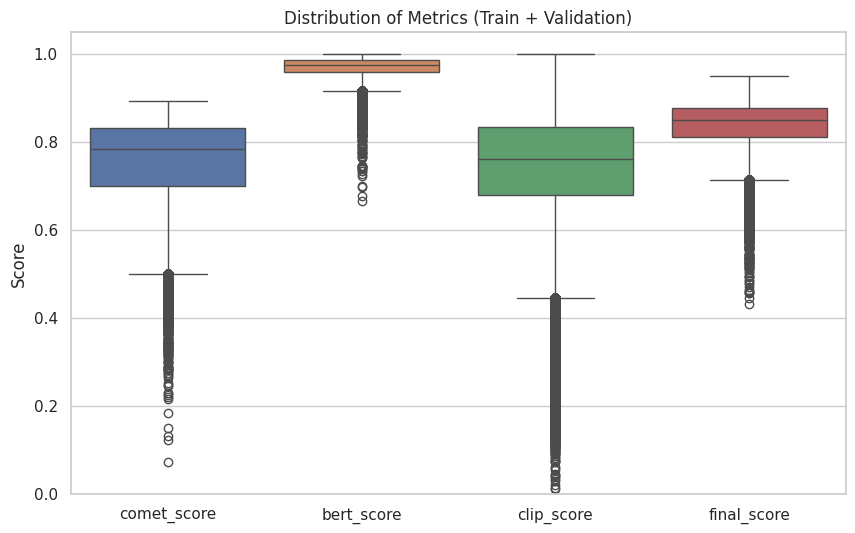

In [73]:
plot_boxplots_from_dataset(dataset, metrics=['comet_score', 'bert_score', 'clip_score', 'final_score'])

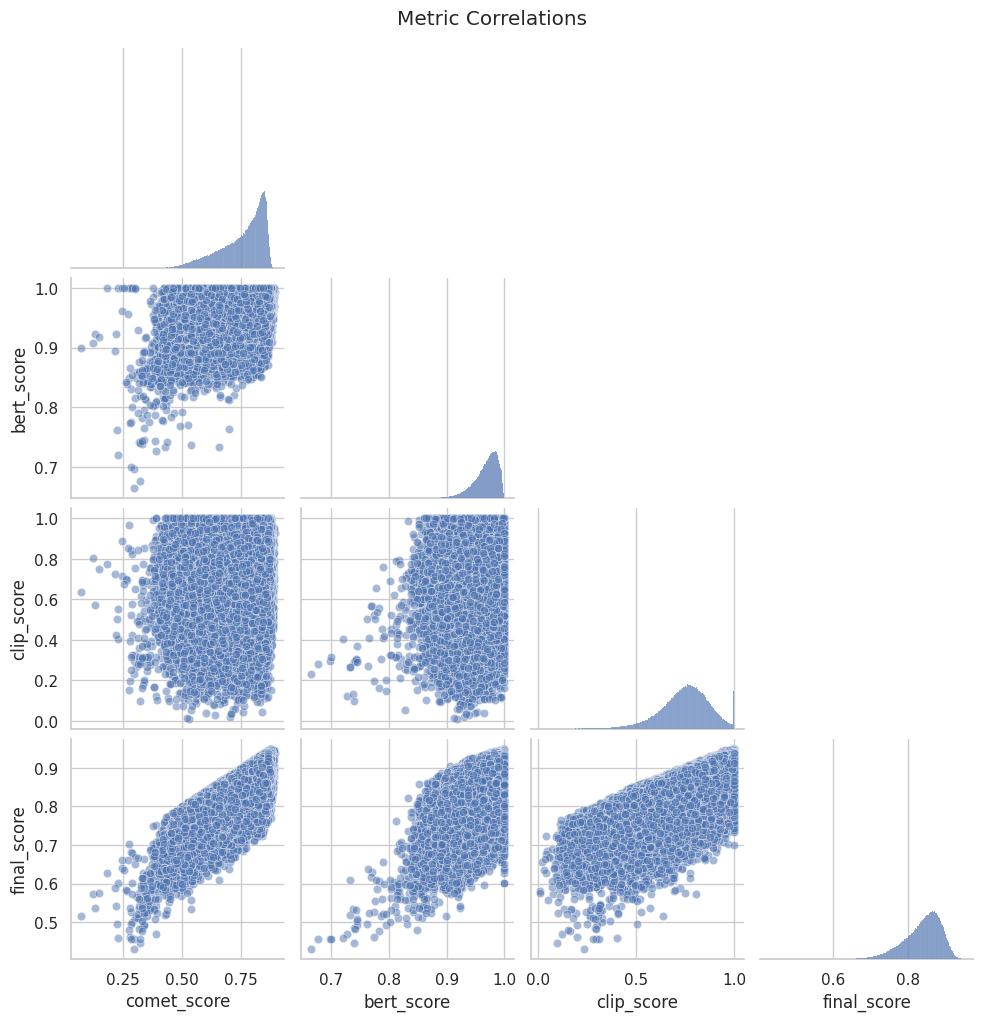

In [75]:
plot_scatter_correlation_from_dataset(dataset, metrics=['comet_score', 'bert_score', 'clip_score', 'final_score'])